## Middleware

Middleware provides a way to more tightly control what happens inside the agent. Middleware is useful for the following :

Tracking agent behavior with logging, analytics and debugging
Trasforming prompts, tool selection and output formatting
Adding retries, fallback and early termination logic
Applying rate llimits, guardrails and PII detection

In [6]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")


In [2]:
import truststore
truststore.inject_into_ssl()

## Summarization Middleware

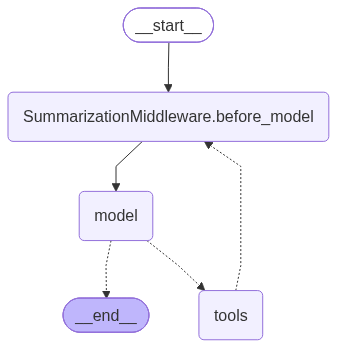

In [10]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import Tool, tool

@tool
def search_hotels(city : str) -> str :
    """Search hotels -returns long response to use more tokens."""
    return f"""" Hotel in {city}
         1. Grand Hotel - 5star, $350/night, spa, pool , gym
         2. City Inn - 4 Star, $200/night, free breakfast
         3. Luxury Suites - 5 Star, $400/night, rooftop bar, gym"""


model = ChatOpenAI(model="gpt-4o",
        api_key=os.getenv("OPENAI_API_KEY"),
        )

middlewareAgent = create_agent(
    model=model,
    tools =[search_hotels],
    debug=True,
    middleware=[SummarizationMiddleware(
        model=model,
        #trigger=("messages", 10),
        # keep=("messages", 3),
        trigger = ("tokens", 550),
        keep = ("tokens", 200),
    )],
    checkpointer=InMemorySaver(),
)

### Message based summarization
middlewareAgent



In [11]:
## Run with thread Id
config = {"configurable": {"thread_id": "test1"}}

def count_tokens(messages) :
    total_chars = sum (len(str(m.content)) for m in messages)
    return total_chars // 4 # 4 chars - 1 token

In [14]:
cities = ["paris", "london", "new york", "tokyo", "dubai", "Singapore"]

for city in cities :
    response = middlewareAgent.invoke({"messages": [HumanMessage(content=f"Find hotels in {city}")]},
                config = config
                )
    tokens = count_tokens(response["messages"])
    print(f" {city}, ~{tokens} tokens, {len(response['messages'])} messages")
    print(f"{response['messages']}")     

[values] {'messages': [HumanMessage(content="Here is a summary of the conversation to date:\n\n## SESSION INTENT\nThe user's primary goal is to find hotel options in different cities, including Paris, London, New York, Tokyo, and now Dubai.\n\n## SUMMARY\n- Hotel options were researched and provided for Paris, London, New York, and Tokyo.\n- Options for Paris, London, and New York included:\n  - Grand Hotel ($350/night)\n  - City Inn ($200/night)\n  - Luxury Suites ($400/night)\n- Tokyo options:\n  - Grand Hotel: 5-star, $350/night, spa, pool, gym\n  - City Inn: 4-star, $200/night, free breakfast\n  - Luxury Suites: 5-star, $400/night, rooftop bar, gym\n\n## ARTIFACTS\nNone\n\n## NEXT STEPS\nFind hotel options in Dubai.", additional_kwargs={'lc_source': 'summarization'}, response_metadata={}, id='a3af6f89-6a64-437c-b306-90aea8cbcd02'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 16, 'prompt_tokens': 389, 'total_toke

In [5]:
questions = [
    "What is 2 + 2",
    "What is 10 + 5",
    "What is 9 + 8",
    "What is 2 + 7",
    "What is 100/2",
    "What is 15 - 2",
    "What is 4 *2"
]

for q in questions:
    response = middlewareAgent.invoke({"messages" : [{"role": "user", "content": q}]} , config )
    response["messages"][-1]

[values] {'messages': [HumanMessage(content='What is 2 + 2', additional_kwargs={}, response_metadata={}, id='c424764a-4a32-4e49-8911-447f91b86a14')]}
[updates] {'SummarizationMiddleware.before_model': None}
[updates] {'model': {'messages': [AIMessage(content='2 + 2 equals 4.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 8, 'prompt_tokens': 14, 'total_tokens': 22, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_7bfd4ce6e1', 'id': 'chatcmpl-EY9wBLv9qaRerRKkBYVRoeatncPLt', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a13033-c251-7571-9e44-53732cae86b1-0', tool_calls=[]